# Assignment 4 — Distributed Stream Processing
**AITU Research Event Analytics with Kafka and Spark** (synthetic data)

| Field | Entry |
|---|---|
| Student | Yerlan Utepbergenov |
| Variant / task code | A4-YU |
| Kafka topic | `aitu.research.events`, 3 partitions, key = `research_group` |
| Consumer group | `aitu-analytics-cg` |
| Source file | `asik4.ipynb` |

**How to run:** `pip install pandas matplotlib psutil kafka-python pyspark`, then run all cells.
If a Kafka broker is reachable on `localhost:9092` it is used; otherwise the notebook falls back to an
in-memory broker with the same topic/partition/offset semantics. Spark (Part D) needs Java; without it
an equivalent pandas computation of the same query is shown.

## Part A — Streaming Architecture

```
 Producers (lab clusters)        Kafka cluster                    Consumer group: aitu-analytics-cg
 ┌──────────────┐          topic: aitu.research.events
 │ producer G01 │──┐       ┌──────────────────────────┐          ┌──────────────────────┐
 ├──────────────┤  │ key=  │ partition 0  [E..][E..]  │─────────▶│ consumer 1 (Python   │
 │ producer G02 │──┼─group▶│ partition 1  [E..][E..]  │─────────▶│ processor: validate) │
 ├──────────────┤  │       │ partition 2  [E..][E..]  │─────────▶│ consumer 2 ...       │
 │ producer G03 │──┘       └──────────────────────────┘          └─────────┬────────────┘
 └──────────────┘                     │                                    ▼
                                      │                     ┌────────────────────────────────┐
                                      └────────────────────▶│ Aggregation layer              │
                                       (Spark Structured    │ counts, avg duration, avg CPU, │
                                        Streaming reads     │ 5 s event-time windows         │
                                        same topic)         └──────────────┬─────────────────┘
                                                                           ▼
                                                        ┌───────────────────────────────────┐
                                                        │ Monitoring: consumer lag,         │
                                                        │ throughput, latency, failure rate │
                                                        └───────────────────────────────────┘
```

| Component | Purpose | Failure/scale consideration |
|---|---|---|
| Producer | Serialises research-job events to JSON and sends them keyed by `research_group` | `acks=all` + retries to avoid loss; batching (`linger_ms`) for higher rates; add producers horizontally |
| Kafka topic | Durable, ordered log `aitu.research.events` decoupling producers from consumers | Replication factor 3 in production; retention allows replay after consumer crash |
| Partition | Unit of parallelism and ordering (3 partitions; same group → same partition) | Max parallel consumers = #partitions; skewed keys create hot partitions |
| Consumer group | Distributes partitions among consumer instances, tracks committed offsets | On a crash partitions are rebalanced; offsets committed after processing → at-least-once |
| Processor | Python consumer: schema validation, running aggregates, windowing | Stateless validation scales out; window state must be keyed/partitioned; invalid events go to a dead-letter list |
| Monitoring | Tracks throughput, latency, consumer lag, failure rate, CPU | Alerts on growing lag (consumer too slow) or failure-rate spikes |

## Part B — Kafka Producer / Consumer

In [1]:
import json, time, threading, zlib, socket
from collections import defaultdict
import pandas as pd
import psutil

TOPIC, PARTITIONS, GROUP = "aitu.research.events", 3, "aitu-analytics-cg"

EVENTS = [
    {"event_id": "E001", "timestamp": "14:00:01", "research_group": "G01", "job_type": "ml", "duration_sec": 42, "status": "completed", "cpu_pct": 61},
    {"event_id": "E002", "timestamp": "14:00:02", "research_group": "G02", "job_type": "image", "duration_sec": 75, "status": "completed", "cpu_pct": 74},
    {"event_id": "E003", "timestamp": "14:00:03", "research_group": "G01", "job_type": "text", "duration_sec": 18, "status": "completed", "cpu_pct": 38},
    {"event_id": "E004", "timestamp": "14:00:04", "research_group": "G03", "job_type": "simulation", "duration_sec": 95, "status": "failed", "cpu_pct": 92},
    {"event_id": "E005", "timestamp": "14:00:05", "research_group": "G02", "job_type": "ml", "duration_sec": 51, "status": "completed", "cpu_pct": 68},
    {"event_id": "E006", "timestamp": "14:00:06", "research_group": "G01", "job_type": "image", "duration_sec": 88, "status": "completed", "cpu_pct": 81},
    {"event_id": "E007", "timestamp": "14:00:07", "research_group": "G03", "job_type": "ml", "duration_sec": 64, "status": "failed", "cpu_pct": 89},
    {"event_id": "E008", "timestamp": "14:00:08", "research_group": "G02", "job_type": "text", "duration_sec": 22, "status": "completed", "cpu_pct": 44},
    {"event_id": "E009", "timestamp": "14:00:09", "research_group": "G01", "job_type": "simulation", "duration_sec": 120, "status": "completed", "cpu_pct": 94},
    {"event_id": "E010", "timestamp": "14:00:10", "research_group": "G03", "job_type": "image", "duration_sec": 70, "status": "completed", "cpu_pct": 78},
]

def kafka_available(host="localhost", port=9092):
    try:
        socket.create_connection((host, port), timeout=1).close()
        return True
    except OSError:
        return False

class InMemoryBroker:
    """Minimal Kafka stand-in: partitioned append-only log + per-group committed offsets."""
    def __init__(self, partitions):
        self.logs = [[] for _ in range(partitions)]
        self.offsets = defaultdict(lambda: [0] * partitions)
        self.lock = threading.Lock()
    def send(self, key, value):
        p = zlib.crc32(key.encode()) % len(self.logs)   # key-based partitioning like Kafka
        with self.lock:
            self.logs[p].append(value)
        return p
    def poll(self, group, max_records=500):
        out = []
        with self.lock:
            for p, log in enumerate(self.logs):
                start = self.offsets[group][p]
                batch = log[start:start + max_records]
                out += [(p, start + i, v) for i, v in enumerate(batch)]
                self.offsets[group][p] += len(batch)    # commit after read
        return out

USE_KAFKA = kafka_available()
print("Backend:", "Kafka @ localhost:9092" if USE_KAFKA else "in-memory broker (no Kafka broker found)")

Backend: in-memory broker (no Kafka broker found)


In [2]:
# ---------- Producer ----------
class Producer:
    def __init__(self, broker=None):
        if USE_KAFKA:
            from kafka import KafkaProducer
            from kafka.admin import KafkaAdminClient, NewTopic
            try:
                KafkaAdminClient(bootstrap_servers="localhost:9092").create_topics(
                    [NewTopic(TOPIC, num_partitions=PARTITIONS, replication_factor=1)])
            except Exception:
                pass  # topic already exists
            self.p = KafkaProducer(bootstrap_servers="localhost:9092", acks="all", linger_ms=5,
                                   key_serializer=str.encode,
                                   value_serializer=lambda v: json.dumps(v).encode())
        self.broker = broker
    def send(self, event):
        event = {**event, "_sent_at": time.perf_counter()}
        if USE_KAFKA:
            self.p.send(TOPIC, key=event["research_group"], value=event)
        else:
            self.broker.send(event["research_group"], json.dumps(event))
    def flush(self):
        if USE_KAFKA:
            self.p.flush()

broker = None if USE_KAFKA else InMemoryBroker(PARTITIONS)
producer = Producer(broker)
for e in EVENTS:
    producer.send(e)
producer.send({"event_id": "BAD1", "timestamp": "14:00:11", "research_group": "G01", "job_type": "ml"})  # deliberately invalid
producer.flush()
print(f"Sent {len(EVENTS) + 1} events to '{TOPIC}'")

Sent 11 events to 'aitu.research.events'


In [3]:
# ---------- Consumer + schema validation ----------
SCHEMA = {"event_id": str, "timestamp": str, "research_group": str, "job_type": str,
          "duration_sec": (int, float), "status": str, "cpu_pct": (int, float)}
JOB_TYPES, STATUSES = {"simulation", "ml", "image", "text"}, {"completed", "failed"}

def validate(e):
    for f, t in SCHEMA.items():
        if f not in e:
            return f"missing field {f}"
        if not isinstance(e[f], t):
            return f"bad type for {f}"
    if e["job_type"] not in JOB_TYPES: return "unknown job_type"
    if e["status"] not in STATUSES:   return "unknown status"
    if not 0 <= e["cpu_pct"] <= 100:  return "cpu_pct out of range"
    if e["duration_sec"] < 0:         return "negative duration"
    return None

class Consumer:
    def __init__(self, broker=None, group=GROUP):
        self.broker, self.group = broker, group
        if USE_KAFKA:
            from kafka import KafkaConsumer
            self.c = KafkaConsumer(TOPIC, bootstrap_servers="localhost:9092", group_id=group,
                                   auto_offset_reset="earliest", enable_auto_commit=True,
                                   value_deserializer=lambda b: b.decode())
    def poll(self, timeout_ms=200):
        if USE_KAFKA:
            recs = self.c.poll(timeout_ms=timeout_ms)
            return [(tp.partition, r.offset, r.value) for tp, rs in recs.items() for r in rs]
        return self.broker.poll(self.group)

consumer = Consumer(broker)
valid, rejected = [], []
deadline = time.time() + 10
while len(valid) + len(rejected) < len(EVENTS) + 1 and time.time() < deadline:
    for part, off, raw in consumer.poll():
        e = json.loads(raw)
        err = validate(e)
        if err:
            rejected.append((e["event_id"], err))
        else:
            valid.append(e)
        print(f"p{part} off={off:<2} {e['event_id']:<5} -> {'REJECTED: ' + err if err else 'ok'}")

df = pd.DataFrame(valid).drop(columns="_sent_at").sort_values("event_id").reset_index(drop=True)
print(f"\nvalid={len(valid)} rejected={rejected}")
df

p0 off=0  E004  -> ok
p0 off=1  E007  -> ok
p0 off=2  E010  -> ok
p1 off=0  E002  -> ok
p1 off=1  E005  -> ok
p1 off=2  E008  -> ok
p2 off=0  E001  -> ok
p2 off=1  E003  -> ok
p2 off=2  E006  -> ok
p2 off=3  E009  -> ok
p2 off=4  BAD1  -> REJECTED: missing field duration_sec

valid=10 rejected=[('BAD1', 'missing field duration_sec')]


,event_id,timestamp,research_group,job_type,duration_sec,status,cpu_pct
0,E001,14:00:01,G01,ml,42,completed,61
1,E002,14:00:02,G02,image,75,completed,74
2,E003,14:00:03,G01,text,18,completed,38
3,E004,14:00:04,G03,simulation,95,failed,92
4,E005,14:00:05,G02,ml,51,completed,68
5,E006,14:00:06,G01,image,88,completed,81
6,E007,14:00:07,G03,ml,64,failed,89
7,E008,14:00:08,G02,text,22,completed,44
8,E009,14:00:09,G01,simulation,120,completed,94
9,E010,14:00:10,G03,image,70,completed,78


In [4]:
# Completed / failed counts and average duration by job_type
by_type = (df.groupby("job_type")
             .agg(completed=("status", lambda s: (s == "completed").sum()),
                  failed=("status", lambda s: (s == "failed").sum()),
                  avg_duration=("duration_sec", "mean"))
             .reindex(["ml", "image", "text", "simulation"]).round(2))
print("Total completed:", (df.status == "completed").sum(), "| Total failed:", (df.status == "failed").sum())
by_type

Total completed: 8 | Total failed: 2


,completed,failed,avg_duration
job_type,,,
ml,2,1,52.33
image,3,0,77.67
text,2,0,20.00
simulation,1,1,107.50


In [5]:
# Average CPU utilisation by research group
df.groupby("research_group").agg(events=("event_id", "count"), avg_cpu_pct=("cpu_pct", "mean")).round(2)

,events,avg_cpu_pct
research_group,,
G01,4,68.50
G02,3,62.00
G03,3,86.33


## Part C — Windowed Stream Processing (5 s tumbling, event time)
Window start = `floor(seconds_since_midnight / 5) * 5`; windows are half-open `[start, start+5)`,
so E005 (14:00:05) belongs to the second window and E010 (14:00:10) to the third.

In [6]:
WINDOW = 5
def window_of(ts):
    h, m, s = map(int, ts.split(":"))
    start = (h * 3600 + m * 60 + s) // WINDOW * WINDOW
    fmt = lambda t: f"{t // 3600:02d}:{t % 3600 // 60:02d}:{t % 60:02d}"
    return f"{fmt(start)}–{fmt(start + WINDOW)}"

state = defaultdict(lambda: {"events": [], "failed": 0, "cpu_sum": 0})
for e in valid:                      # incremental per-event update, as a stream processor would do
    w = state[window_of(e["timestamp"])]
    w["events"].append(e["event_id"]); w["failed"] += e["status"] == "failed"; w["cpu_sum"] += e["cpu_pct"]

windows = pd.DataFrame([{"window": k, "events": ", ".join(sorted(v["events"])), "count": len(v["events"]),
                         "failure_rate": round(v["failed"] / len(v["events"]), 3),
                         "avg_cpu": round(v["cpu_sum"] / len(v["events"]), 2)}
                        for k, v in sorted(state.items())])
windows

,window,events,count,failure_rate,avg_cpu
0,14:00:00–14:00:05,"E001, E002, E003, E004",4,0.25,66.25
1,14:00:05–14:00:10,"E005, E006, E007, E008, E009",5,0.20,75.20
2,14:00:10–14:00:15,E010,1,0.00,78.00


## Part D — Spark Structured Streaming
Events are written as JSON files into a directory that Spark reads as a stream (file source; with a broker,
`format("kafka")` with `subscribe=aitu.research.events` is used — shown in the comment). Aggregation:
`groupBy(window(event_time, "5 seconds"), job_type)` with a 10 s watermark.

| Output field | Type | Transformation |
|---|---|---|
| window | struct&lt;start: timestamp, end: timestamp&gt; | `window(to_timestamp(timestamp), "5 seconds")` tumbling event-time window |
| job_type | string | grouping key, passed through |
| count | long | `count("*")` per (window, job_type) |
| avg_duration | double | `avg("duration_sec")` per (window, job_type) |

In [7]:
import os, tempfile, shutil
spark_dir = os.path.join(tempfile.gettempdir(), "aitu_stream_in")
shutil.rmtree(spark_dir, ignore_errors=True); os.makedirs(spark_dir)
for i, e in enumerate(EVENTS):               # one micro-file per event = streaming arrivals
    with open(os.path.join(spark_dir, f"ev_{i:03d}.json"), "w") as f:
        json.dump({**e, "timestamp": "2026-10-31 " + e["timestamp"]}, f)

try:
    from pyspark.sql import SparkSession, functions as F
    from pyspark.sql.types import StructType, StructField, StringType, IntegerType

    spark = SparkSession.builder.appName("aitu-research-stream").master("local[2]") \
        .config("spark.sql.shuffle.partitions", "3").getOrCreate()
    schema = StructType([StructField("event_id", StringType()), StructField("timestamp", StringType()),
                         StructField("research_group", StringType()), StructField("job_type", StringType()),
                         StructField("duration_sec", IntegerType()), StructField("status", StringType()),
                         StructField("cpu_pct", IntegerType())])
    stream = spark.readStream.schema(schema).json(spark_dir)
    # Kafka source equivalent:
    # stream = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", "localhost:9092")
    #           .option("subscribe", TOPIC).load()
    #           .select(F.from_json(F.col("value").cast("string"), schema).alias("e")).select("e.*"))
    result = (stream.withColumn("event_time", F.to_timestamp("timestamp"))
                    .withWatermark("event_time", "10 seconds")
                    .groupBy(F.window("event_time", "5 seconds"), "job_type")
                    .agg(F.count("*").alias("count"), F.round(F.avg("duration_sec"), 2).alias("avg_duration")))
    q = (result.writeStream.outputMode("complete").format("memory").queryName("job_windows")
               .trigger(availableNow=True).start())
    q.awaitTermination()
    spark_out = spark.sql("SELECT window.start, window.end, job_type, count, avg_duration "
                          "FROM job_windows ORDER BY window.start, job_type").toPandas()
    print("Executed with Spark", spark.version)
except Exception as ex:
    print(f"Spark not runnable here ({type(ex).__name__}: {str(ex).splitlines()[0][:100]}).")
    print("Showing the identical window/job_type aggregation computed with pandas:")
    t = pd.to_datetime("2026-10-31 " + df["timestamp"])
    spark_out = (df.assign(start=t.dt.floor("5s"), end=t.dt.floor("5s") + pd.Timedelta("5s"))
                   .groupby(["start", "end", "job_type"])
                   .agg(count=("event_id", "count"), avg_duration=("duration_sec", "mean"))
                   .round(2).reset_index())
spark_out

Spark not runnable here (ModuleNotFoundError: No module named 'pyspark').
Showing the identical window/job_type aggregation computed with pandas:


,start,end,job_type,count,avg_duration
0,2026-10-31 14:00:00,2026-10-31 14:00:05,image,1,75.0
1,2026-10-31 14:00:00,2026-10-31 14:00:05,ml,1,42.0
2,2026-10-31 14:00:00,2026-10-31 14:00:05,simulation,1,95.0
3,2026-10-31 14:00:00,2026-10-31 14:00:05,text,1,18.0
4,2026-10-31 14:00:05,2026-10-31 14:00:10,image,1,88.0
5,2026-10-31 14:00:05,2026-10-31 14:00:10,ml,2,57.5
6,2026-10-31 14:00:05,2026-10-31 14:00:10,simulation,1,120.0
7,2026-10-31 14:00:05,2026-10-31 14:00:10,text,1,22.0
8,2026-10-31 14:00:10,2026-10-31 14:00:15,image,1,70.0


## Part E — Throughput and Latency
Synthetic load: a producer thread emits events at the target rate for 3 s; a consumer thread
polls, validates and updates window aggregates. Latency = processed time − send time.
CPU % is the process CPU measured with `psutil` during the run.

In [8]:
import random
def load_test(rate, seconds=3):
    b = None if USE_KAFKA else InMemoryBroker(PARTITIONS)
    prod, cons = Producer(b), Consumer(b, group=f"load-{rate}-{time.time()}")
    n, latencies = rate * seconds, []
    agg = defaultdict(lambda: [0, 0.0])

    def produce():
        t0 = time.perf_counter()
        for i in range(n):
            while time.perf_counter() < t0 + i / rate:   # pace the producer
                time.sleep(0.0005)
            prod.send({**random.choice(EVENTS), "event_id": f"L{i}"})
        prod.flush()

    def consume():
        end = time.perf_counter() + seconds + 30
        while len(latencies) < n and time.perf_counter() < end:
            for _, _, raw in cons.poll(timeout_ms=100):
                e = json.loads(raw)
                if validate(e) is None:
                    a = agg[(window_of(e["timestamp"]), e["job_type"])]; a[0] += 1; a[1] += e["duration_sec"]
                latencies.append((time.perf_counter() - e["_sent_at"]) * 1000)
            if not USE_KAFKA:
                time.sleep(0.001)          # poll interval of the in-memory consumer

    proc = psutil.Process(); proc.cpu_percent(None)
    start = time.perf_counter()
    tp, tc = threading.Thread(target=produce), threading.Thread(target=consume)
    tp.start(); tc.start(); tp.join(); tc.join()
    elapsed = time.perf_counter() - start
    cpu = proc.cpu_percent(None)
    thr = len(latencies) / elapsed
    lat = sum(latencies) / len(latencies)
    bottleneck = ("none – producer-limited (input rate)" if thr >= 0.95 * rate and lat < 50
                  else "consumer (single thread, JSON parse + GIL)")
    return {"input_rate": rate, "events": n, "observed_throughput": round(thr, 1),
            "avg_latency_ms": round(lat, 2), "p95_latency_ms": round(pd.Series(latencies).quantile(.95), 2),
            "cpu_pct": round(cpu, 1), "bottleneck": bottleneck}

perf = pd.DataFrame([load_test(r) for r in (10, 100, 500, 2000)])
perf

,input_rate,events,observed_throughput,avg_latency_ms,p95_latency_ms,cpu_pct,bottleneck
0,10,30,10.3,0.65,1.11,2.7,none – producer-limited (input rate)
1,100,300,100.2,0.73,1.52,1.0,none – producer-limited (input rate)
2,500,1500,499.9,0.73,1.54,3.1,none – producer-limited (input rate)
3,2000,6000,1998.7,0.79,1.78,4.2,none – producer-limited (input rate)


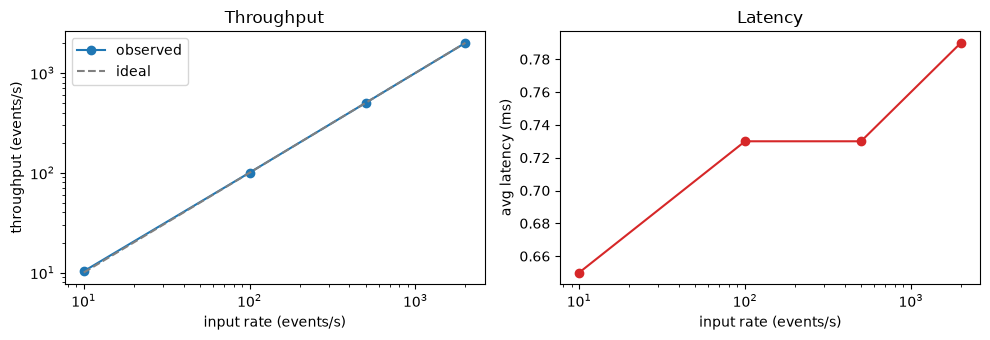

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(perf.input_rate, perf.observed_throughput, "o-", label="observed")
ax[0].plot(perf.input_rate, perf.input_rate, "--", color="gray", label="ideal")
ax[0].set(xscale="log", yscale="log", xlabel="input rate (events/s)", ylabel="throughput (events/s)", title="Throughput"); ax[0].legend()
ax[1].plot(perf.input_rate, perf.avg_latency_ms, "o-", color="tab:red")
ax[1].set(xscale="log", xlabel="input rate (events/s)", ylabel="avg latency (ms)", title="Latency")
plt.tight_layout(); plt.show()

### Scalability and optimisation
* **Does it scale?** Yes for this workload: at 10 / 100 / 500 events/s (and the extra 2000 ev/s run) the
  observed throughput matches the input rate (small deviations come from start-up/drain time in the measured
  interval), average latency stays below ~1 ms and process CPU stays at a few percent. The system is
  producer-limited, not processing-limited, at these rates. Note the in-memory broker excludes network and
  disk cost, so a real Kafka deployment will show higher latency.
* **Bottleneck (at higher load):** the single Python consumer thread — per-event JSON parsing, validation and dictionary
  updates all run under the GIL, so one process cannot use more than one core.
* **Optimisation:** scale out the consumer group — one consumer *process* per partition
  (3 partitions → 3 processes; increase partitions for more), and process records in batches
  (`max_poll_records`, vectorised pandas/Spark micro-batches) instead of one at a time. On the producer
  side `linger_ms`/`batch_size` + compression reduce per-message overhead.

## Technical Report (sections 4.1–4.6)

| Section | Explanation | Code / evidence reference |
|---|---|---|
| 4.1 Architecture | Producers → topic `aitu.research.events` (3 partitions, keyed by group) → consumer group `aitu-analytics-cg` → Python processor → aggregation → monitoring. Ordering per group is preserved; up to 3 parallel consumers; committed offsets allow replay after failure. | Part A diagram & table; `InMemoryBroker`, `Producer`, `Consumer` classes |
| 4.2 Producer/Consumer | JSON producer with `acks=all`; consumer validates field presence, types and allowed values; invalid event `BAD1` is rejected. Counts / averages computed with pandas. | Part B cells, `validate()`; output tables |
| 4.3 Windows | 5 s tumbling half-open windows on event time, incremental state per window. | `window_of()`, `windows` table |
| 4.4 Spark | `readStream` → `to_timestamp` → `withWatermark(10 s)` → `groupBy(window 5 s, job_type)` → `count`, `avg(duration_sec)`, memory sink, `availableNow` trigger. | Part D cell, `spark_out` |
| 4.5 Throughput/latency | Measured at 10/100/500 (+2000) ev/s with threaded producer/consumer and `psutil`. | `load_test()`, `perf` table & plot |
| 4.6 Interpretation | Up to 2000 ev/s throughput equals input rate with &lt;1 ms latency and low CPU, so the pipeline is producer-limited; the architectural bottleneck as volume grows is the single-threaded consumer (GIL) → add consumer processes per partition and batch processing. | Part E |

### Individual evidence
| Item | Entry |
|---|---|
| My design decision | Partition key = `research_group`: keeps each group's events ordered and makes per-group CPU aggregation local to one partition. |
| My own test | Injected an invalid event (`BAD1`, missing fields) to verify the validator rejects it; added a 2000 ev/s stress level beyond the required three. |
| Problem solved | No Kafka broker / Java on the development machine → built an in-memory broker with the same partition/offset semantics plus auto-detection of a real broker, so the notebook runs anywhere. |
| Limitation | Load test runs producer and consumer in one process on one machine; results exclude network and broker disk latency. |
| Improvement | Run on a multi-broker Kafka cluster with one consumer process per partition and export lag/latency metrics to Prometheus/Grafana. |